# RoadScan experiment 20 — E3 augmentation ablation

Compare four YOLOv8s fine-tuning recipes: all three augmentations enabled, without Mosaic, without HSV jitter, and without horizontal flip. Each ablation changes one augmentation group relative to the control. This evaluates the contribution of each group conditional on the other two; it does not measure all interactions.

All arms restart from the same original published RDD2022 checkpoint and use the exact frozen team split: 8,999 training images and 1,977 China development images. The adopted run-17 fine-tuned model and its frozen confidence 0.46 remain unchanged. No local or US images are used.

**Protocol fixed before results:** seven full epochs per arm, seed 42, batch 16, resolution 640, AdamW, lr0 and warmup_bias_lr 0.0001. Early stopping is disabled and Mosaic closing is disabled in all arms so that the on/off contrast is present throughout this short study. Primary endpoint: detection mAP50-95 of the final epoch; secondary: mAP50 and per-class AP. Best checkpoints are retained for diagnosis only. Every arm has the same training budget and schedule. This is a short, single-seed development study, not proof of statistical significance or independent local generalization.

## 1. Audit the frozen dataset
Check images, labels, country assignments and hashes against saved run 17. Preserve the original split and record the exact data used.

In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import hashlib, json, math, shutil, platform
import numpy as np
import pandas as pd
from PIL import Image
import yaml
from IPython.display import display, Markdown

BASE = Path('/kaggle/input/notebooks/rimasabunasser/17-roadscan-gentle-finetuning')
REF = BASE/'artifacts_run17'
assert (REF/'requested_training_settings.json').is_file(), 'Attach run 14 version 1 outputs.'
SOURCE = BASE/'run17_team_v2_data'
ROOT = Path('/kaggle/working/e3_data')
ART = Path('/kaggle/working/artifacts_e3')
ART.mkdir(exist_ok=True)
CLASSES = ['D00','D10','D20','D40']
assert SOURCE.is_dir(), 'Attach the original team sample9000 v2 notebook output.'
original_manifest = (REF/'original_team_sample9000_list.txt').read_text().splitlines()
assert len(original_manifest)==len(set(original_manifest))==8999
jobs=[]
for split,expected in [('train',8999),('val',1977)]:
    images={p.stem:p for p in (SOURCE/split/'images').glob('*.jpg')}
    labels={p.stem:p for p in (SOURCE/split/'labels').glob('*.txt')}
    assert images.keys()==labels.keys() and len(images)==expected, (split,len(images),len(labels))
    if split=='train':
        assert set(images)==set(original_manifest)
        assert Counter(s.split('_')[0] for s in images)=={'Japan':4000,'India':3500,'Czech':1499}
    else:
        assert all(s.startswith('China_MotorBike_') for s in images)
    for folder in ['images','labels']:
        (ROOT/split/folder).mkdir(parents=True,exist_ok=True)
    jobs.extend((split,stem,images[stem],labels[stem]) for stem in sorted(images))

def stage_and_audit(job):
    split,stem,image,label=job
    raw=label.read_text()
    present=[0]*4
    boxes=0
    for line in raw.splitlines():
        if not line.strip():
            continue
        row=list(map(float,line.split()))
        assert len(row)==5 and all(math.isfinite(x) for x in row),str(label)
        c,x,y,w,h=row
        assert c==int(c) and 0<=c<4 and 0<w<=1 and 0<h<=1,str(label)
        assert x-w/2>=-1e-4 and y-h/2>=-1e-4 and x+w/2<=1.0001 and y+h/2<=1.0001,str(label)
        present[int(c)]=1
        boxes+=1
    with Image.open(image) as im:
        im.load()
        width,height=im.size
    digest=hashlib.sha256(image.read_bytes()).hexdigest()
    for src,folder in [(image,'images'),(label,'labels')]:
        shutil.copy2(src,ROOT/split/folder/src.name)
    return dict(split=split,stem=stem,country=stem.split('_')[0],sha256=digest,width=width,height=height,boxes=boxes,empty=int(boxes==0),**dict(zip(CLASSES,present)))

records=[]
with ThreadPoolExecutor(max_workers=8) as pool:
    for i,row in enumerate(pool.map(stage_and_audit,jobs),1):
        records.append(row)
        if i%1000==0:
            print('Audited and staged:',i,'/',len(jobs),flush=True)
manifest=pd.DataFrame(records)
train_hash=set(manifest.loc[manifest.split.eq('train'),'sha256'])
val_hash=set(manifest.loc[manifest.split.eq('val'),'sha256'])
assert not train_hash & val_hash, 'Exact image leakage across train and validation.'
assert set(manifest.loc[manifest.split.eq('train'),'country']).isdisjoint(set(manifest.loc[manifest.split.eq('val'),'country']))
manifest.to_csv(ART/'manifest.csv',index=False)
shutil.copy2(REF/'original_team_sample9000_list.txt',ART/'original_team_sample9000_list.txt')
manifest_digest=hashlib.sha256((chr(10).join(sorted(original_manifest))+chr(10)).encode()).hexdigest()
(ART/'sample_manifest_sha256.txt').write_text(manifest_digest)
DATA=ROOT/'data.yaml'
DATA.write_text(yaml.safe_dump(dict(path=str(ROOT),train='train/images',val='val/images',names=dict(enumerate(CLASSES))),sort_keys=False))
shutil.copy2(DATA,ART/'data.yaml')
summary=manifest.groupby(['split','country']).agg(images=('stem','size'),empty=('empty','sum'),**{c:(c,'sum') for c in CLASSES}).reset_index()
summary.to_csv(ART/'data_summary.csv',index=False)
display(summary)
(ART/'protocol.json').write_text(json.dumps(dict(train=8999,validation=1977,train_countries=['Japan','India','Czech'],validation_country='China_MotorBike',sample_source=str(BASE),sample_sha256=manifest_digest,US_status='not opened in this run; external checkpoint pretraining exposure is unknown',local_images='test only; never train or tune',test_evaluated=False,selection='exact original team v2 sample; enriched for D10/D40',split='country-disjoint; exact hashes checked; no verified drive IDs',baseline_comparison='same image assignments; baseline implementation and threshold protocol must be verified before claiming a controlled comparison'),indent=2))
print('DATA_READY',flush=True)
display(Markdown('**Data interpretation.** The exact team v2 sample passed image decoding, label geometry, country separation and exact cross-split duplicate checks. Japan/India/Czech are training countries; China MotorBike is development validation. This preserves the team sample and does not use US or local test images. Sampling enriches rare classes, so training frequencies are not population prevalence.'))

frozen14 = pd.read_csv(REF/'manifest.csv')
assert manifest.set_index(['split','stem']).sha256.to_dict() == frozen14.set_index(['split','stem']).sha256.to_dict(), 'Image hashes differ from run 14.'

assert manifest_digest == 'd88d9d98c1e9e81f21930b6f97fa49c6ceec218938834b9ace757a24baedaffc'
print('E3_DATA_VERIFIED',flush=True)


Audited and staged: 1000 / 10976
Audited and staged: 2000 / 10976
Audited and staged: 3000 / 10976
Audited and staged: 4000 / 10976
Audited and staged: 5000 / 10976
Audited and staged: 6000 / 10976
Audited and staged: 7000 / 10976
Audited and staged: 8000 / 10976
Audited and staged: 9000 / 10976
Audited and staged: 10000 / 10976


,split,country,images,empty,D00,D10,D20,D40
0,train,Czech,1499,427,764,300,129,154
1,train,India,3500,500,1012,60,1586,1530
2,train,Japan,4000,500,989,2240,1741,1390
3,val,China,1977,43,1419,738,486,164


DATA_READY


**Data interpretation.** The exact team v2 sample passed image decoding, label geometry, country separation and exact cross-split duplicate checks. Japan/India/Czech are training countries; China MotorBike is development validation. This preserves the team sample and does not use US or local test images. Sampling enriches rare classes, so training frequencies are not population prevalence.

E3_DATA_VERIFIED


## 2. Freeze the four recipes
Verify the original initialization hash and save every arm's settings before training. Train sequentially on one GPU. Inherit the explicit run-17 recipe, but use seven fixed epochs and no early stopping for every arm. All metrics here belong to China development validation.

In [2]:
import sys, subprocess, importlib.metadata, time, gc
try: installed=importlib.metadata.version('ultralytics')
except importlib.metadata.PackageNotFoundError: installed=None
if installed!='8.4.177':subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics==8.4.177'])
import torch, ultralytics
from ultralytics import YOLO
assert ultralytics.__version__=='8.4.177'
assert torch.cuda.is_available(), 'Enable GPU before running.'
WEIGHTS=BASE/'run17_model_comparison/original_published.pt'
EXPECTED_SHA='565aae6915e34e4f7f4c44dac0bdcf9fff21b83c4adc74cc97ca09cc31882ce8'
assert hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()==EXPECTED_SHA
probe=YOLO(str(WEIGHTS));assert [probe.names[i] for i in range(4)] in [CLASSES,['longitudinal_crack','transverse_crack','alligator_crack','pothole']]
del probe
common=json.loads((REF/'requested_training_settings.json').read_text())
common.update(data=str(DATA),project='/kaggle/working/runs_e3',epochs=7,patience=0,close_mosaic=0,save_period=-1,plots=True,exist_ok=False,device=0)
assert (common['batch'],common['imgsz'],common['seed'],common['lr0'],common['warmup_bias_lr'])==(16,640,42,0.0001,0.0001)
assert (common['mosaic'],common['fliplr'],common['hsv_h'],common['hsv_s'],common['hsv_v'])==(1.0,0.5,0.015,0.7,0.4)
ARMS={'all_on':{},'no_mosaic':{'mosaic':0.0},'no_hsv':{'hsv_h':0.0,'hsv_s':0.0,'hsv_v':0.0},'no_horizontal_flip':{'fliplr':0.0}}
recipes={name:dict(common,**changes,name=name) for name,changes in ARMS.items()}
protocol=dict(experiment='E3',run=20,checkpoint_sha256=EXPECTED_SHA,epochs_per_arm=7,primary_endpoint='final epoch detection mAP50-95',seed=42,arms=recipes,local_images_used=False,US_images_used=False,adopted_model_changed=False,limitations=['single seed','short fixed training horizon','China development reused','external pretraining overlap unknown'])
(ART/'e3_protocol.json').write_text(json.dumps(protocol,indent=2))
(ART/'environment.json').write_text(json.dumps(dict(python=platform.python_version(),ultralytics=ultralytics.__version__,torch=torch.__version__,gpu=torch.cuda.get_device_name(0)),indent=2))
display(pd.DataFrame([dict(arm=k,**{f:v[f] for f in ['epochs','mosaic','hsv_h','hsv_s','hsv_v','fliplr','close_mosaic']}) for k,v in recipes.items()]))
display(Markdown('**Preparation interpretation.** The initialization bytes, class mapping and dataset match the recorded source. Four settings files are frozen before results. Each ablation differs from the control only in the named augmentation group. The seven-epoch horizon differs from the historical run-17 schedule, so the new control must be rerun.'))
print('E3_RECIPES_FROZEN',flush=True)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 3.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,arm,epochs,mosaic,hsv_h,hsv_s,hsv_v,fliplr,close_mosaic
0,all_on,7,1.0,0.015,0.7,0.4,0.5,0
1,no_mosaic,7,0.0,0.015,0.7,0.4,0.5,0
2,no_hsv,7,1.0,0.000,0.0,0.0,0.5,0
3,no_horizontal_flip,7,1.0,0.015,0.7,0.4,0.0,0


**Preparation interpretation.** The initialization bytes, class mapping and dataset match the recorded source. Four settings files are frozen before results. Each ablation differs from the control only in the named augmentation group. The seven-epoch horizon differs from the historical run-17 schedule, so the new control must be rerun.

E3_RECIPES_FROZEN


## 3. Train and evaluate each arm
Reload the same original checkpoint before each arm. Complete seven epochs, then evaluate `last.pt` at confidence floor 0.001 and NMS IoU 0.7 using the same validation procedure. Save results after each arm so completed comparisons remain available if a later arm fails. No deployment threshold is retuned.

In [3]:
rows=[];class_rows=[]
for name,settings in recipes.items():
    print('E3_ARM_START',name,flush=True)
    assert hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()==EXPECTED_SHA
    model=YOLO(str(WEIGHTS));start=time.monotonic()
    model.train(**settings)
    run=Path(model.trainer.save_dir)
    history=pd.read_csv(run/'results.csv');history.columns=history.columns.str.strip()
    assert len(history)==7, f'{name}: incomplete fixed training budget'
    elapsed=time.monotonic()-start
    last=run/'weights/last.pt';assert last.is_file()
    folder=ART/name;folder.mkdir(exist_ok=True)
    for file in [last,run/'weights/best.pt',run/'results.csv',run/'args.yaml',run/'results.png']:
        if file.exists():shutil.copy2(file,folder/file.name)
    del model;gc.collect();torch.cuda.empty_cache()
    evaluator=YOLO(str(last))
    metrics=evaluator.val(data=str(DATA),split='val',imgsz=640,batch=16,device=0,workers=2,conf=0.001,iou=0.7,max_det=300,plots=True,project='/kaggle/working/evaluation_e3',name=name,exist_ok=False)
    row=dict(arm=name,epochs=7,training_seconds=elapsed,checkpoint_sha256=hashlib.sha256(last.read_bytes()).hexdigest(),mAP50=float(metrics.box.map50),mAP50_95=float(metrics.box.map),precision=float(metrics.box.mp),recall=float(metrics.box.mr))
    rows.append(row)
    for i,code in enumerate(CLASSES):class_rows.append(dict(arm=name,damage_code=code,AP50=float(metrics.box.ap50[i]),AP50_95=float(metrics.box.ap[i])))
    (folder/'metrics.json').write_text(json.dumps(row,indent=2))
    pd.DataFrame(rows).to_csv(ART/'e3_comparison.csv',index=False)
    pd.DataFrame(class_rows).to_csv(ART/'e3_per_class.csv',index=False)
    display(pd.DataFrame(rows))
    display(Markdown(f"**{name} result.** Seven epochs completed. Final-epoch mAP50-95 is {row['mAP50_95']:.2%} and mAP50 is {row['mAP50']:.2%}. These are development scores; the final table will compare this arm with the new all-on control."))
    print('E3_ARM_COMPLETE',json.dumps(row),flush=True)
    del evaluator,metrics;gc.collect();torch.cuda.empty_cache()
assert len(rows)==4


E3_ARM_START all_on
New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/e3_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=7, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/7       4.3G      1.591       1.35      1.432         30        640: 100% ━━━━━━━━━━━━ 563/563 5.1it/s 1:50
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 4.3it/s 14.5s
                   all       1977       4650      0.916      0.923      0.959      0.658

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/7       4.3G      1.582      1.342      1.435         23        640: 100% ━━━━━━━━━━━━ 563/563 5.1it/s 1:50
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 62/62 4.3it/s 14.5s
                   all       1977       4650      0.921      0.922      0.959      0.654

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/7       4.3G      1.574      1.325      1.425         20        640: 100% ━━━━━━━━━━━━ 563/563 5.1it/s 1:50
                 Class     Images  Instances      Box(

,arm,epochs,training_seconds,checkpoint_sha256,mAP50,mAP50_95,precision,recall
0,all_on,7,925.247024,f545a04623a660315783e4a5ff496e76356027f88c75c4...,0.958591,0.653027,0.918026,0.920621


**all_on result.** Seven epochs completed. Final-epoch mAP50-95 is 65.30% and mAP50 is 95.86%. These are development scores; the final table will compare this arm with the new all-on control.

E3_ARM_COMPLETE {"arm": "all_on", "epochs": 7, "training_seconds": 925.2470244589999, "checkpoint_sha256": "f545a04623a660315783e4a5ff496e76356027f88c75c4410e4aeee1023877a6", "mAP50": 0.9585909477183958, "mAP50_95": 0.6530270407651321, "precision": 0.9180262600489292, "recall": 0.9206208516479517}
E3_ARM_START no_mosaic
New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/e3_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, drop

... (5 outputs left out)

E3_ARM_COMPLETE {"arm": "no_hsv", "epochs": 7, "training_seconds": 900.013083673, "checkpoint_sha256": "6401ec80732f5bfe609cf2520c00b58b5f49aba9743a6cf1df14dab6515e9ed9", "mAP50": 0.9589209354760655, "mAP50_95": 0.6525107900062246, "precision": 0.9212396535371096, "recall": 0.9222594196839771}
E3_ARM_START no_horizontal_flip
New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/e3_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False,

,arm,epochs,training_seconds,checkpoint_sha256,mAP50,mAP50_95,precision,recall
0,all_on,7,925.247024,f545a04623a660315783e4a5ff496e76356027f88c75c4...,0.958591,0.653027,0.918026,0.920621
1,no_mosaic,7,899.026289,4b3fb51e50856cb4a3dea5eedb5b1dc85aca1b216e8288...,0.956069,0.645853,0.906513,0.922677
2,no_hsv,7,900.013084,6401ec80732f5bfe609cf2520c00b58b5f49aba9743a6c...,0.958921,0.652511,0.921240,0.922259
3,no_horizontal_flip,7,903.411769,be5899af428301b23d94ac7645e01372af1cc892a14247...,0.956973,0.650502,0.915008,0.921247


**no_horizontal_flip result.** Seven epochs completed. Final-epoch mAP50-95 is 65.05% and mAP50 is 95.70%. These are development scores; the final table will compare this arm with the new all-on control.

E3_ARM_COMPLETE {"arm": "no_horizontal_flip", "epochs": 7, "training_seconds": 903.4117692350001, "checkpoint_sha256": "be5899af428301b23d94ac7645e01372af1cc892a14247dc8af7b622bbb616db", "mAP50": 0.9569731515600903, "mAP50_95": 0.650502316899536, "precision": 0.9150082942862154, "recall": 0.9212465101895023}


## 4. Compare, interpret and save the decision
Report each ablation's change from the all-on control, plus a figure and a short engineering interpretation. Positive ablation delta means removing that group helped in this particular short experiment; negative delta favors keeping it. Do not replace the adopted model automatically.

,arm,epochs,training_seconds,checkpoint_sha256,mAP50,mAP50_95,precision,recall,delta_vs_all_on_pp
0,all_on,7,925.247024,f545a04623a660315783e4a5ff496e76356027f88c75c4...,0.958591,0.653027,0.918026,0.920621,0.000000
1,no_mosaic,7,899.026289,4b3fb51e50856cb4a3dea5eedb5b1dc85aca1b216e8288...,0.956069,0.645853,0.906513,0.922677,-0.717445
2,no_hsv,7,900.013084,6401ec80732f5bfe609cf2520c00b58b5f49aba9743a6c...,0.958921,0.652511,0.921240,0.922259,-0.051625
3,no_horizontal_flip,7,903.411769,be5899af428301b23d94ac7645e01372af1cc892a14247...,0.956973,0.650502,0.915008,0.921247,-0.252472


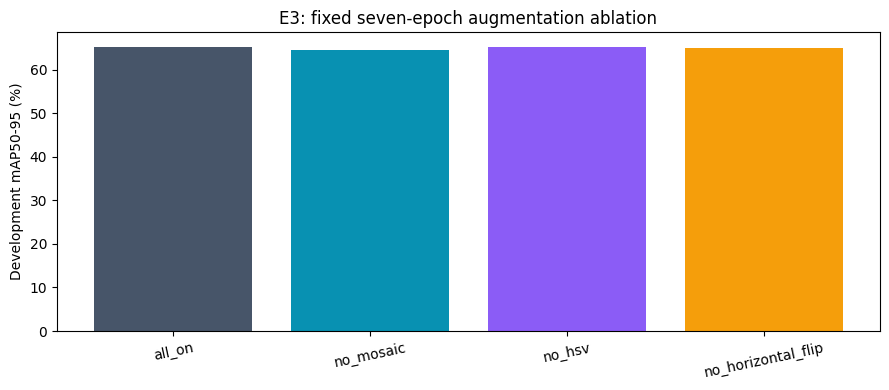

**Final interpretation.** Removing mosaic reduced mAP50-95 by 0.72 percentage points relative to all-on. This is a single-seed, seven-epoch development observation, not a universal causal ranking. Removing hsv reduced mAP50-95 by 0.05 percentage points relative to all-on. This is a single-seed, seven-epoch development observation, not a universal causal ranking. Removing horizontal_flip reduced mAP50-95 by 0.25 percentage points relative to all-on. This is a single-seed, seven-epoch development observation, not a universal causal ranking. Horizontal flips are plausible for many crack and pothole appearances but reverse traffic handedness and signs; retain only when these semantics are irrelevant. Mild HSV jitter approximates illumination changes, while extreme hue/saturation changes are unrealistic. Mosaic creates artificial seams and changes damage scale/context, so inspect its effect on small cracks. Vertical flips put road geometry upside down and are physically implausible for normal forward-facing road images; flipud remains zero. Validation and test images receive no training augmentation. The adopted model remains frozen pending independent local evaluation.

E3_EXPERIMENT_COMPLETE {"status": "complete", "experiment": "E3", "run": 20, "protocol": {"experiment": "E3", "run": 20, "checkpoint_sha256": "565aae6915e34e4f7f4c44dac0bdcf9fff21b83c4adc74cc97ca09cc31882ce8", "epochs_per_arm": 7, "primary_endpoint": "final epoch detection mAP50-95", "seed": 42, "arms": {"all_on": {"data": "/kaggle/working/e3_data/data.yaml", "imgsz": 640, "epochs": 7, "patience": 0, "batch": 16, "device": 0, "workers": 2, "seed": 42, "deterministic": true, "optimizer": "AdamW", "lr0": 0.0001, "lrf": 0.01, "cos_lr": true, "warmup_epochs": 3, "weight_decay": 0.0005, "mosaic": 1.0, "close_mosaic": 0, "mixup": 0.0, "scale": 0.5, "translate": 0.1, "degrees": 0.0, "fliplr": 0.5, "flipud": 0.0, "hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4, "cache": false, "amp": true, "save": true, "save_period": -1, "plots": true, "project": "/kaggle/working/runs_e3", "name": "all_on", "exist_ok": false, "warmup_bias_lr": 0.0001}, "no_mosaic": {"data": "/kaggle/working/e3_data/data.yaml", "im

In [4]:
import matplotlib.pyplot as plt
comparison=pd.DataFrame(rows);control=float(comparison.loc[comparison.arm.eq('all_on'),'mAP50_95'].iloc[0])
comparison['delta_vs_all_on_pp']=(comparison.mAP50_95-control)*100
comparison.to_csv(ART/'e3_comparison.csv',index=False)
display(comparison)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(comparison.arm,comparison.mAP50_95*100,color=['#475569','#0891b2','#8b5cf6','#f59e0b']);ax.set_ylabel('Development mAP50-95 (%)');ax.set_title('E3: fixed seven-epoch augmentation ablation');ax.tick_params(axis='x',rotation=12);fig.tight_layout();fig.savefig(ART/'e3_augmentation_comparison.png',dpi=160);plt.show()
interpretations=[]
for row in comparison.to_dict('records'):
    if row['arm']=='all_on':continue
    change=row['delta_vs_all_on_pp'];direction='improved' if change>0 else 'reduced' if change<0 else 'did not change'
    interpretations.append(f"Removing {row['arm'].removeprefix('no_')} {direction} mAP50-95 by {abs(change):.2f} percentage points relative to all-on. This is a single-seed, seven-epoch development observation, not a universal causal ranking.")
physical='Horizontal flips are plausible for many crack and pothole appearances but reverse traffic handedness and signs; retain only when these semantics are irrelevant. Mild HSV jitter approximates illumination changes, while extreme hue/saturation changes are unrealistic. Mosaic creates artificial seams and changes damage scale/context, so inspect its effect on small cracks. Vertical flips put road geometry upside down and are physically implausible for normal forward-facing road images; flipud remains zero. Validation and test images receive no training augmentation.'
report='# E3 augmentation ablation\n\n'+comparison.to_markdown(index=False)+'\n\n'+' '.join(interpretations)+'\n\n'+physical+'\n\nAll arms restart from the same original RDD2022 weights and use the frozen team split. Primary endpoint is final-epoch mAP50-95 after seven fixed epochs. Other augmentations and training settings are held constant. This estimates each group conditional on the other enabled groups; interactions and multi-seed uncertainty were not measured. China is development data and external pretraining overlap is unknown. No US/local images were used. The adopted run17 checkpoint and confidence 0.46 remain unchanged; no automatic replacement is justified by this study alone.\n\nAttribution: published initialization SreekarAditya/yolo-rdd2022-benchmark (CC BY 4.0 according to publisher); RDD2022, Arya et al.; preserve applicable Ultralytics terms.\n'
(ART/'E3_AUGMENTATION.md').write_text(report)
summary=dict(status='complete',experiment='E3',run=20,protocol=protocol,results=comparison.to_dict('records'),per_class=class_rows,interpretation=interpretations,physical_validity=physical,adopted_model_changed=False,local_images_used=False,US_images_used=False)
(ART/'e3_results.json').write_text(json.dumps(summary,indent=2))
display(Markdown('**Final interpretation.** '+' '.join(interpretations)+' '+physical+' The adopted model remains frozen pending independent local evaluation.'))
print('E3_EXPERIMENT_COMPLETE',json.dumps(summary),flush=True)
